# 01 Exploratory data analysis: MasakhaNEWS Lingala

**Goal:** understand the data before modelling. How many articles per topic, how long they are, how big
the vocabulary is, how much French is mixed in, and how consistent the spelling is. Each finding here
motivates a modelling choice later (class weights, character n-grams, accent stripping, truncation length).

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Change this to your own GitHub repository before running in Colab
REPO_URL = "https://github.com/YOUR-GITHUB-USERNAME/lingala-news-classification.git"

if IN_COLAB and not Path("lingala-news-classification").exists():
    !git clone -q {REPO_URL}
if IN_COLAB:
    %cd lingala-news-classification
    %pip install -q -r requirements.txt

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

Working directory: /home/claude/lingala-news-classification


In [2]:
import re
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config, data_loading, plots
from src.data_preparation import main as prepare_data
from src.text_processing import strip_accents, tokenise

if not config.TRAIN_FILE.exists():
    prepare_data()

train, validation, test = data_loading.load_all_splits()
everything = pd.concat([train.assign(split="train"), validation.assign(split="validation"), test.assign(split="test")], ignore_index=True)
print("Articles:", len(train), len(validation), len(test), "| total", len(everything))
train.head(3)

Articles: 608 87 175 | total 870


,category,headline,text,content,url
0,health,Bakonzi ya Etats-Unis basengi bakolo basala ba...,Bakonzi ya bokolongono ya Etats-Unis basengi n...,Bakonzi ya Etats-Unis basengi bakolo basala ba...,https://www.voalingala.com/a/bakonzi-ya-etats-...
1,business,FMI elobi kokitisa budget ezali malamu,FMI (Fonds monétaire international) etalisi ko...,FMI elobi kokitisa budget ezali malamu. FMI (F...,https://www.voalingala.com/a/fmi-elobi-kokitis...
2,health,Bituma na Ebola bitelemi na Beni,Botelemeli ya bavandi ya Beni mpe Butembo mpo ...,Bituma na Ebola bitelemi na Beni. Botelemeli y...,https://www.voalingala.com/a/bituma-na-ebola-b...


## 1. Class distribution

split,train,validation,test,share_of_all
category,,,,
politics,350,50,100,0.575
health,135,19,39,0.222
sports,66,10,19,0.109
business,57,8,17,0.094


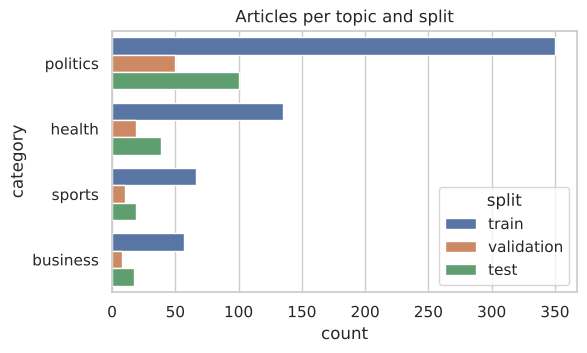

In [3]:
counts = pd.crosstab(everything["category"], everything["split"]).reindex(config.LABELS)[["train", "validation", "test"]]
counts["share_of_all"] = (counts.sum(axis=1) / counts.to_numpy().sum()).round(3)
display(counts)

figure, axis = plt.subplots(figsize=(6, 3.4))
sns.countplot(data=everything, y="category", order=config.LABELS, hue="split", ax=axis)
axis.set_title("Articles per topic and split")
plots.save(figure, "eda", "class_distribution.png");

**Finding:** politics is 57% of the data and business only 9%. A model that always says *politics*
already gets 57% accuracy, which is why **macro-F1** (each class weighted equally) is our main metric
and why we try **class weights**. The validation set has only 8 business and 10 sports articles, so
validation scores are noisy; we add cross-validation for the fast models and several seeds for the neural ones.

## 2. Article length

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
politics,500.0,187.0,73.0,67.0,134.0,177.0,223.0,641.0
health,193.0,176.0,61.0,38.0,135.0,164.0,207.0,348.0
sports,95.0,145.0,56.0,59.0,110.0,136.0,162.0,357.0
business,82.0,185.0,56.0,70.0,148.0,174.0,228.0,336.0


Share of articles with at most 300 words: 0.947


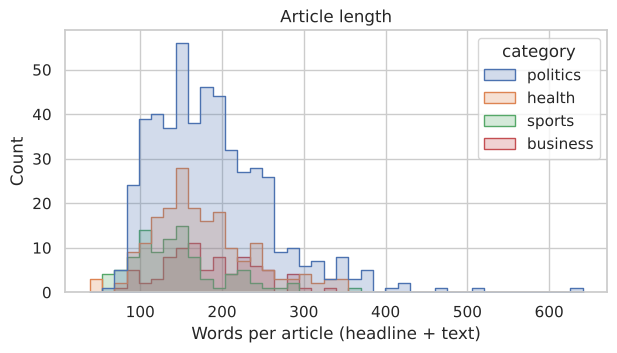

In [4]:
everything["words"] = everything["content"].str.split().str.len()
display(everything.groupby("category")["words"].describe().reindex(config.LABELS).round(0))

figure, axis = plt.subplots(figsize=(7, 3.4))
sns.histplot(data=everything, x="words", hue="category", hue_order=config.LABELS, bins=40, element="step", ax=axis)
axis.set_xlabel("Words per article (headline + text)")
axis.set_title("Article length")
plots.save(figure, "eda", "article_length.png")
print("Share of articles with at most 300 words:", round((everything["words"] <= 300).mean(), 3))

**Finding:** articles are short news items (median about 165 words; the longest is 641). We cap the RNN input at
300 words, which keeps about 95% of articles whole. Transformer subword tokenisers split Lingala words into several
pieces, so we test head-only versus head+tail truncation at 512 subword tokens.

## 3. Vocabulary: size, rare words and unseen words

Training tokens: 110,639  |  distinct words: 10,316
Words seen only once (hapax legomena): 5,485 (53% of the vocabulary)
Share of validation tokens never seen in training: 6.9%
Share of test tokens never seen in training:       6.5%


Most frequent words: ['na', 'ya', 'mpe', 'mpo', 'ba', 'ete', 'ye', 'yango', 'bato', 'm', 'te', 'moko', 'tshisekedi', 'rdc', 'mboka', 'congo', 'baye', 'bango', 'ezali', 'mokonzi', 'nsima', 'président', 'mokambi', 'misala', 'mingi']


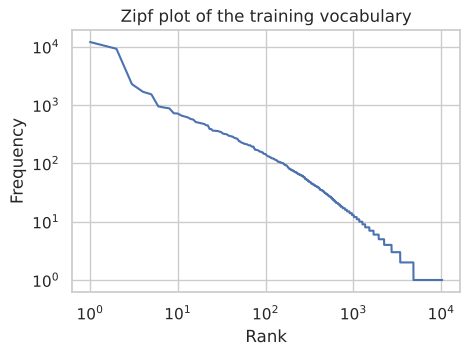

In [5]:
train_tokens = [w for text in train["content"] for w in tokenise(text)]
vocabulary = Counter(train_tokens)
hapax = sum(1 for c in vocabulary.values() if c == 1)
print(f"Training tokens: {len(train_tokens):,}  |  distinct words: {len(vocabulary):,}")
print(f"Words seen only once (hapax legomena): {hapax:,} ({hapax/len(vocabulary):.0%} of the vocabulary)")

def unseen_rate(frame):
    tokens = [w for text in frame["content"] for w in tokenise(text)]
    return np.mean([w not in vocabulary for w in tokens])

print(f"Share of validation tokens never seen in training: {unseen_rate(validation):.1%}")
print(f"Share of test tokens never seen in training:       {unseen_rate(test):.1%}")

ranks = np.arange(1, len(vocabulary) + 1)
frequencies = np.array(sorted(vocabulary.values(), reverse=True))
figure, axis = plt.subplots(figsize=(5, 3.4))
axis.loglog(ranks, frequencies)
axis.set_xlabel("Rank")
axis.set_ylabel("Frequency")
axis.set_title("Zipf plot of the training vocabulary")
plots.save(figure, "eda", "zipf_plot.png")
print("Most frequent words:", [w for w, _ in vocabulary.most_common(25)])

**Finding:** with about 110k training tokens, half the vocabulary appears only once and about 7% of validation and test
tokens were never seen in training. Whole-word models cannot use those words at all. This motivates
**character n-grams** (shared stems and prefixes) and **subword tokenisers** (transformers). The most frequent words are
function words (*ya* 'of', *na* 'with/and', *mpe* 'and', *ete* 'that'); TF-IDF down-weights them automatically.

## 4. Code-mixing with French

In [6]:
# Lingala news from VOA borrows many French words: institutions, titles, sport and economics.
# A rough indicator: words with French-only characters or endings. This undercounts
# (unaccented loans such as "budget" are missed) but shows the trend.
french_pattern = re.compile(r"[éèêëàâçôûùîï]|(?:tion|ment|ique|eur|aire)s?$")

def french_like_share(text):
    tokens = tokenise(text)
    return np.mean([bool(french_pattern.search(t)) for t in tokens]) if tokens else 0

everything["french_like_share"] = everything["content"].apply(french_like_share)
display(everything.groupby("category")["french_like_share"].mean().reindex(config.LABELS).round(3).to_frame("mean share of French-like tokens"))
print("Example:", train.loc[train["category"] == "business", "content"].iloc[0][:300])

,mean share of French-like tokens
category,
politics,0.044
health,0.029
sports,0.048
business,0.044


Example: FMI elobi kokitisa budget ezali malamu. FMI (Fonds monétaire international) etalisi kobanga na yango lolenge bosaleli budget ya RDC ezali kokende mpe ekanisi ete ekozala malamu kokitisa budget. "Lolenge budget esalelami kino kati kati ya sanza ya février ezali kopesa bobangi likolo ya bozito etiyami


**Finding:** even this crude count, which misses unaccented loans such as *budget*, *match* or *club*, finds French in
every topic (3-5% of tokens). Many of the topic words are French (*procès*, *ambassade*, *budget*, *Léopards*, *symptômes*),
often with a Lingala plural prefix attached (*ba stocks*, *ba symptômes*). Many topic signals are in fact French words.
This helps bag-of-words models, and it also means multilingual transformers that know French can transfer knowledge.

## 5. Spelling and accent variation

In [7]:
# Group words that become identical when accents are removed
groups = {}
for word in vocabulary:
    groups.setdefault(strip_accents(word), set()).add(word)
variants = {base: forms for base, forms in groups.items() if len(forms) > 1}
print(f"{len(variants)} words appear in two or more accent spellings in the training data, e.g.:")
for base, forms in list(sorted(variants.items(), key=lambda kv: -sum(vocabulary[f] for f in kv[1])))[:15]:
    print("  ", {form: vocabulary[form] for form in forms})

118 words appear in two or more accent spellings in the training data, e.g.:
   {'été': 18, 'ete': 947}
   {'president': 43, 'président': 448, 'prèsident': 1}
   {'felix': 37, 'félix': 272}
   {'états': 5, 'etats': 204}
   {'democratique': 12, 'démocratique': 194, 'dèmocratique': 1}
   {'état': 24, 'etat': 106}
   {'assemblee': 3, 'assemblée': 106}
   {'général': 72, 'general': 14}
   {'léopards': 69, 'leopards': 11}
   {'senat': 8, 'sénat': 71}
   {'a': 49, 'à': 7}
   {'ministere': 1, 'ministère': 49}
   {'mabele': 43, 'mabélé': 3}
   {'maï': 16, 'mai': 27}
   {'présidence': 40, 'presidence': 2}


**Finding:** the same word appears with and without accents (for example *ete* / *été* 'that'). Lingala tone marks are
optional in everyday writing, and the open vowels ɛ/ɔ are usually written e/o. We therefore test **accent stripping**
as a preprocessing experiment: it merges these spellings, but it can also merge different French words.

## 6. Time period covered

In [8]:
years = Counter(int(y) for text in everything["content"] for y in re.findall(r"\b(20[012]\d)\b", text))
print("Years mentioned in the articles:", dict(sorted(years.items())))
for keyword in ["covid", "ebola", "tshisekedi", "kabila", "trump", "biden"]:
    print(f"{keyword:11s} appears in {everything['content'].str.lower().str.contains(keyword).sum():3d} articles")

Years mentioned in the articles: {2000: 1, 2001: 1, 2002: 9, 2003: 8, 2004: 2, 2005: 4, 2006: 1, 2007: 3, 2008: 1, 2009: 6, 2010: 8, 2011: 4, 2012: 6, 2013: 9, 2014: 10, 2015: 11, 2016: 20, 2017: 23, 2018: 66, 2019: 83, 2020: 94, 2021: 59, 2022: 50, 2023: 32, 2024: 2, 2025: 2, 2026: 1}
covid       appears in 149 articles
ebola       appears in  71 articles
tshisekedi  appears in 294 articles
kabila      appears in 112 articles
trump       appears in  47 articles
biden       appears in  34 articles


## 7. Data quality notes

In [9]:
print("Headlines starting with a lower-case letter (possible scraping cut):",
      everything.loc[everything["headline"].str[0].str.islower(), "headline"].tolist())
print("Shortest articles:")
display(everything.nsmallest(3, "words")[["category", "headline", "words"]])

Headlines starting with a lower-case letter (possible scraping cut): ['avid Blattner abandaki kosamba na TGI/Gombe']
Shortest articles:


,category,headline,words
717,health,COVID-19: Botinda mituna na bino nyonso,38
109,health,COVID-19 na ndako ya pape François,47
735,health,Leader nani azali kosunga bandeko komibatela n...,53


The MasakhaNEWS paper reports a Fleiss' kappa of 0.56 between the two Lingala annotators
(Adelani et al., 2023), which is only moderate agreement (Landis & Koch, 1977). Some labels are therefore debatable, for example court cases about
company directors labelled *business*, or parliamentary decisions about COVID-19 labelled *health*. This sets a ceiling on
achievable accuracy and is important for the error analysis.

## 8. Words that separate the topics

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

vectoriser = CountVectorizer(token_pattern=r"(?u)[^\W\d_]+|\d+", min_df=3)
counts_matrix = vectoriser.fit_transform(train["content"])
names = vectoriser.get_feature_names_out()
rows = []
for label in config.LABELS:
    in_class = (train["category"] == label).to_numpy()
    scores, _ = chi2(counts_matrix, in_class)
    # chi-squared also rewards words that are unusually RARE in a class; keep only over-represented words
    over_represented = np.asarray(counts_matrix[in_class].mean(axis=0)).ravel() > np.asarray(counts_matrix.mean(axis=0)).ravel()
    scores = np.where(over_represented, scores, 0)
    rows.append({"topic": label, "most distinctive words (chi-squared)": ", ".join(names[np.argsort(scores)[::-1][:12]])})
pd.DataFrame(rows)

,topic,most distinctive words (chi-squared)
0,politics,"maponami, mokonzi, tshisekedi, kabila, lingomb..."
1,health,"ebola, covid, 19, bokono, mangwele, oms, dr, b..."
2,sports,"léopards, club, match, finale, caf, basani, 0,..."
3,business,"bad, gertler, fmi, banque, dan, pétrole, misol..."


**Finding:** sports and health have very clear vocabularies (*Léopards*, *match*, *équipe*; *Ebola*, *coronavirus*, *bokono*
'disease'). Politics and business share names (Tshisekedi, RDC, gouvernement), which predicts that most confusions will be
**business ↔ politics** and **health ↔ politics** (government responses to Ebola/COVID-19).

Years mentioned in the articles are concentrated in 2018–2023, so health news is dominated by Ebola and COVID-19. A model may
learn "Ebola = health" rather than a general notion of health, a **temporal bias** we come back to in the limitations.